# 3. Cross-Dataset Comparison: Blood (Liquid Biopsy) vs. Solid Tumor Tissue
### Simple Plain-English Walkthrough & Comparison

In this notebook, we combine **both datasets** together to understand the central problem of our capstone project:

| Dataset | What is it? | Tumor Content | The Big Challenge |
| :--- | :--- | :--- | :--- |
| **TCGA (Notebook 2)** | Solid Tumor Tissue cut directly from surgery | **Very High (50% - 80% tumor)** | Easy to see copy number changes (loud signal). But requires invasive surgery! |
| **PRJNA795275 (Notebook 1)** | Blood Plasma liquid biopsy | **Extremely Low (0.1% - 1% tumor)** | Safe & non-invasive (just a blood draw). But the tumor signal is a tiny whisper drowned out by healthy blood DNA! |

**The Goal of our AI:**  
Can we detect cancer from a blood draw even when the tumor fraction is as low as **0.1% to 1%**?

In [1]:
# Step 1: Load standard Python tools
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## Step 1: Side-by-Side Comparison of Both Datasets

In [2]:
# Load Blood manifest
blood_df = pd.read_csv("../../data/metadata/sample_sheet.csv")

# Load Tissue file list
tcga_files = list(Path("../../references/tcga_cnv").glob("*.seg.v2.txt"))
tissue_projects = pd.Series([f.name.split("_")[0] for f in tcga_files]).value_counts()

print("=== DATASET 1: Blood Plasma cfDNA (PRJNA795275) ===")
print(f"Total Blood Samples: {len(blood_df)}")
print(f"Healthy Controls:    {(blood_df['condition'] == 'Healthy').sum()}")
print(f"Lung Cancer Blood:   {(blood_df['condition'] == 'Cancer').sum()}")

print("\n=== DATASET 2: Solid Tumor Tissue (TCGA Reference) ===")
print(f"Total Tissue Samples: {len(tcga_files)}")
print(f"Lung Tumors (LUAD):   {tissue_projects.get('TCGA-LUAD', 0)}")
print(f"Kidney Tumors (KIRC): {tissue_projects.get('TCGA-KIRC', 0)}")
print(f"Brain Tumors (GBM):   {tissue_projects.get('TCGA-GBM', 0)}")

=== DATASET 1: Blood Plasma cfDNA (PRJNA795275) ===
Total Blood Samples: 69
Healthy Controls:    28
Lung Cancer Blood:   41

=== DATASET 2: Solid Tumor Tissue (TCGA Reference) ===
Total Tissue Samples: 500
Lung Tumors (LUAD):   296
Kidney Tumors (KIRC): 156
Brain Tumors (GBM):   48


## Step 2: The 'Whisper in a Stadium' Analogy (Signal vs. Noise)
**In simple words:**  
- In solid tumor tissue, 60% of the DNA has extra or missing copies. You can see it with your naked eyes.  
- In early-stage cancer blood plasma, **99.5% of the DNA comes from healthy white blood cells**, and only **0.5% comes from the cancer**.  
- Standard clinical tools like **ichorCNA** look for big bumps. When the tumor is < 3%, ichorCNA thinks the person is completely healthy (False Negative)!

Let's visualize this difference:

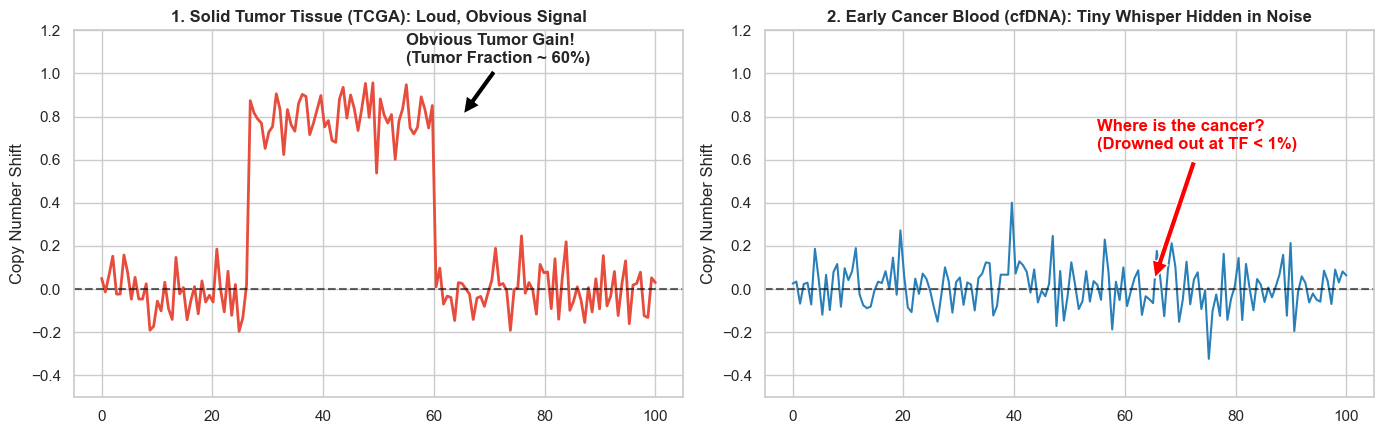

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Simulate what a chromosome looks like in pure tissue vs early cancer blood
np.random.seed(42)
x = np.linspace(0, 100, 150)

# Solid Tissue: Big obvious copy number jump
tissue_signal = np.random.normal(0, 0.1, 150)
tissue_signal[40:90] += 0.8  # Large copy gain (+0.8)

axes[0].plot(x, tissue_signal, color="#e74c3c", lw=2)
axes[0].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[0].set_title("1. Solid Tumor Tissue (TCGA): Loud, Obvious Signal", fontweight="bold")
axes[0].set_ylabel("Copy Number Shift")
axes[0].set_ylim(-0.5, 1.2)
axes[0].annotate("Obvious Tumor Gain!\n(Tumor Fraction ~ 60%)", xy=(65, 0.8), xytext=(55, 1.05),
                 arrowprops=dict(facecolor="black", shrink=0.05), fontweight="bold")

# Blood Plasma: Drowned in healthy DNA noise
blood_signal = np.random.normal(0, 0.1, 150)
blood_signal[40:90] += 0.015  # Tiny dilution (+0.015) drowned in noise!

axes[1].plot(x, blood_signal, color="#2980b9", lw=1.5)
axes[1].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[1].set_title("2. Early Cancer Blood (cfDNA): Tiny Whisper Hidden in Noise", fontweight="bold")
axes[1].set_ylabel("Copy Number Shift")
axes[1].set_ylim(-0.5, 1.2)
axes[1].annotate("Where is the cancer?\n(Drowned out at TF < 1%)", xy=(65, 0.02), xytext=(55, 0.65),
                 arrowprops=dict(facecolor="red", shrink=0.05), fontweight="bold", color="red")

plt.tight_layout()
plt.show()

## Step 3: How Our Project Bridges the Gap (In Silico Dilution)
Because true clinical blood samples come in random unknown tumor fractions, we use **In Silico Dilution**:
1. We take a high-confidence cancer blood sample.
2. We mix its reads with healthy control reads (`CTR`) at exact mathematical tiers:
   - **10% Tumor Fraction:** Late stage (easy to detect).
   - **5% Tumor Fraction:** Middle stage.
   - **1% Tumor Fraction:** Early Stage (where traditional tools start failing).
   - **0.1% Tumor Fraction:** Very Early Stage (where our AI rescues detection using fragment lengths and end motifs!).

In [4]:
# Show the target dilution ladder
dilution_tiers = pd.DataFrame([
    {"Tumor Fraction": "10%", "Clinical Stage": "Stage IV (Advanced)", "Standard ichorCNA": "Detects easily (100%)", "Our AI Goal": "100%"},
    {"Tumor Fraction": "5%",  "Clinical Stage": "Stage III", "Standard ichorCNA": "Detects (~70-80%)", "Our AI Goal": "> 95%"},
    {"Tumor Fraction": "1%",  "Clinical Stage": "Stage II (Early)", "Standard ichorCNA": "Fails (< 20% sensitivity)", "Our AI Goal": "Rescued to > 70%"},
    {"Tumor Fraction": "0.1%","Clinical Stage": "Stage I (Very Early)", "Standard ichorCNA": "Completely Fails (0%)", "Our AI Goal": "Rescued to > 40%"}
])

display(dilution_tiers)

,Tumor Fraction,Clinical Stage,Standard ichorCNA,Our AI Goal
0,10%,Stage IV (Advanced),Detects easily (100%),100%
1,5%,Stage III,Detects (~70-80%),> 95%
2,1%,Stage II (Early),Fails (< 20% sensitivity),Rescued to > 70%
3,0.1%,Stage I (Very Early),Completely Fails (0%),Rescued to > 40%


## Step 4: Beyond Copy Numbers — Why Fragmentomics is the Secret Weapon
When copy numbers are too small to see in blood, what do we look at? **Fragmentomics!**
1. **Fragment Lengths:** Cancer cfDNA fragments are shorter (100-150 bp) than healthy cfDNA fragments (167 bp).
2. **End Motifs:** The letters at the cut ends of the DNA (like `CCCA`, `CCAA`) change when cancer nucleases are active.
3. **Multimodal AI:** Combining fragment lengths + motifs + copy numbers allows XGBoost, LightGBM, and Neural Networks to catch cancer when copy numbers alone fail.

In [5]:
# Summary diagram of the pipeline
print("=" * 75)
print("CAPSTONE WORKFLOW INTEGRATION SUMMARY:")
print("=" * 75)
print("1. PRJNA795275 (Blood cfDNA)  --> Provides real healthy & lung cancer reads")
print("2. TCGA-LUAD (Tumor Tissue)   --> Provides chromosomal alteration boundaries")
print("3. In Silico Dilution Engine  --> Blends reads at 10%, 5%, 1%, 0.1% TF")
print("4. Multimodal Feature Fusion  --> Length ratios + 256 End motifs + ichorCNA")
print("5. Zero-Leakage GroupKFold   --> Guarantees honest clinical cross-validation")
print("6. Streamlit Dashboard        --> Displays sensitivity rescue curves")
print("=" * 75)

CAPSTONE WORKFLOW INTEGRATION SUMMARY:
1. PRJNA795275 (Blood cfDNA)  --> Provides real healthy & lung cancer reads
2. TCGA-LUAD (Tumor Tissue)   --> Provides chromosomal alteration boundaries
3. In Silico Dilution Engine  --> Blends reads at 10%, 5%, 1%, 0.1% TF
4. Multimodal Feature Fusion  --> Length ratios + 256 End motifs + ichorCNA
5. Zero-Leakage GroupKFold   --> Guarantees honest clinical cross-validation
6. Streamlit Dashboard        --> Displays sensitivity rescue curves


## Summary of Notebook 3:
1. **Tissue (TCGA)** gives us pure cancer signals and teaches us where cancer alters chromosomes.
2. **Blood (PRJNA795275)** gives us real liquid biopsy reads from healthy people and lung cancer patients.
3. Comparing them demonstrates the **Low Tumor-Fraction Gap**: blood signal is 100x weaker than tissue signal.
4. Our AI bridges this gap using fragmentomics and tested *in silico* dilutions.